## import functions/libraries

In [1]:
import geopandas as gpd
import rasterio, pandas

from functions.estimate_biomass import estimate_biomass
from functions.get_diameter import *
from functions.get_treespecies import *
from functions.get_treeheight import *
from functions.histogram_treespecies import *
import matplotlib.pyplot as plt
import os

## define basepath/settings

In [2]:
basepath = "/home/berberic/Documents/allometry"
export_results = False
export_plots = False

## load polygons

In [3]:
trees21 = gpd.read_file(f"{basepath}/trees/bonn_2021_vital.geojson").head(5)
trees16 = gpd.read_file(f"{basepath}/trees/bonn_2016_vital.geojson").head(200)

/home/berberic/Documents/code/biomass/.venv/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 1510 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(
/home/berberic/Documents/code/biomass/.venv/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 1510 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(


## calculate diameter

In [4]:
trees16 = get_diameter(trees16)
trees21 = get_diameter(trees21)

diameter derived
diameter derived


## get tree species

In [5]:
trees16 = get_treespecies(polygon=trees16, raster_path= f"{basepath}/treespecies/treespecies_blickensdoerfer.tif", data_source="blickensdoerfer")
trees21 = get_treespecies(polygon=trees21, raster_path=f"{basepath}/treespecies/treespecies_2021_bonn.tif")

In [6]:
trees16["treespecies"].isna().sum()
trees16["treetype"].isna().sum()

np.int64(0)

## get tree height

In [7]:
treeheight_info = "from_file"

if treeheight_info == "from_file":

    treeheights16 = get_treeheight_fromfile(polygon=trees16, raster_path=f"{basepath}/treeheight/CHM_1m_bonn.tif")
    treeheights21 = get_treeheight_fromfile(polygon=trees21, raster_path=f"{basepath}/treeheight/CHM_1m_bonn.tif")

if treeheight_info == "from_dlr":

    treeheights16 = get_treeheight_fromDLR(polygon=trees16, year = 2016, aoi_path=f"{basepath}/aoi.geojson")
    treeheights21 = get_treeheight_fromDLR(polygon=trees21, year = 2021, aoi_path=f"{basepath}/aoi.geojson")

treeheight derived
treeheight derived


In [8]:
print("--- 2016 INPUT DATA CHECK ---", flush=True)
print("Diameters (Min/Max/Mean):", treeheights16["diameter"].min(), treeheights16["diameter"].max(), treeheights16["diameter"].mean(), flush=True)
print("Heights (Min/Max/Mean):", treeheights16["treeheight"].min(), treeheights16["treeheight"].max(), treeheights16["treeheight"].mean(), flush=True)
print(f"Number of zero or negative diameters: {(treeheights16['diameter'] <= 0).sum()}", flush=True)
print(f"Number of missing (NaN) heights: {treeheights16['treeheight'].isna().sum()}", flush=True)
print("-----------------------------", flush=True)

--- 2016 INPUT DATA CHECK ---
Diameters (Min/Max/Mean): 0.11744721766331857 10.772328072768047 6.217131590317713
Heights (Min/Max/Mean): 0.0 0.22611026763916015 0.15335658288558127
Number of zero or negative diameters: 0
Number of missing (NaN) heights: 0
-----------------------------


In [9]:
# handle zeros in treeheight by using mean instead
remove_zeros = False

if remove_zeros: # Trees with 0 as treeheight, get the mean treeheight instead
    treeheights16.loc[treeheights16["treeheight"] == 0, "treeheight"] = treeheights16["treeheight"].mean()
    treeheights21.loc[treeheights21["treeheight"] == 0, "treeheight"] = treeheights21["treeheight"].mean()

plot_treeheight = False

if plot_treeheight:
    treeheights16["treeheight"].hist(bins=25)
    plt.show()
    treeheights21["treeheight"].hist(bins=25)
    plt.show()

## estimate biomass

In [10]:
biomass16 = estimate_biomass(treeheights16)
biomass21 = estimate_biomass(treeheights21)

biomass derived
biomass derived


In [11]:
if export_results:
    biomass16.to_file(f"f{basepath}/results/biomass/biomass16.geojson", driver="GeoJSON")
    biomass21.to_file(f"f{basepath}/results/biomass/biomass21.geojson", driver="GeoJSON")

In [12]:
total_deadAGB16 = sum(biomass16["AGB"])
print(f"dead tree biomass 2016:     {round(total_deadAGB16/1000)} tonnen")
total_deadAGB21 = sum(biomass21["AGB"])
print(f"dead tree biomass 2021:    {round(total_deadAGB21/1000)} tonnen")

dead tree biomass 2016:     0 tonnen
dead tree biomass 2021:    0 tonnen


## Plots

In [13]:
# Ensure the plots directory exists before saving
os.makedirs(f"{basepath}results/plots", exist_ok=True)

print(f"Mean biomass per dead tree in 2016: {biomass16['AGB'].mean()}")
print(f"Mean biomass per dead tree in 2021: {biomass21['AGB'].mean()}")

# 1. AGB Histogram 2016
biomass16["AGB"].hist(bins=50)
plt.title("per Tree AGB in 2016")
plt.xlabel("Tree AGB (kg)")
plt.ylabel("Number of Tree AGBs in 2016")
if export_plots: plt.savefig(f"{basepath}results/plots/agb_2016_hist.png", bbox_inches='tight')
plt.close()

# 2. AGB Histogram 2021
biomass21["AGB"].hist(bins=50)
plt.title("per Tree AGB in 2021")
plt.xlabel("Tree AGB (kg)")
plt.ylabel("Number of Tree AGBs in 2021")
if export_plots: plt.savefig(f"{basepath}results/plots/agb_2021_hist.png", bbox_inches='tight')
plt.close()

# 3. Tree Height vs Crown Diameter 2016
biomass16.plot.scatter(x="treeheight", y="diameter", figsize=(8, 5), alpha=0.5, title="Tree Height vs. Crown Diameter in 2016")
plt.xlabel("Tree Height (m)")
plt.ylabel("Crown Diameter (m)")
if export_plots: plt.savefig(f"{basepath}results/plots/height_vs_diameter_2016.png", bbox_inches='tight')
plt.close()

# 4. Tree Height vs Crown Diameter 2021
biomass21.plot.scatter(x="treeheight", y="diameter", figsize=(8, 5), alpha=0.5, title="Tree Height vs. Crown Diameter in 2021")
plt.xlabel("Tree Height (m)")
plt.ylabel("Crown Diameter (m)")
if export_plots: plt.savefig(f"{basepath}results/plots/height_vs_diameter_2021.png", bbox_inches='tight')
plt.close()

# 5. Crown Diameter vs AGB 2016
biomass16.plot.scatter(x="diameter", y="AGB", figsize=(8, 5), alpha=0.5, title="Diameter vs. AGB in 2016")
plt.xlabel("Crown Diameter (m)")
plt.ylabel("AGB (kg)")
if export_plots: plt.savefig(f"{basepath}results/plots/diameter_vs_agb_2016.png", bbox_inches='tight')
plt.close()

# 6. Crown Diameter vs AGB 2021
biomass21.plot.scatter(x="diameter", y="AGB", figsize=(8, 5), alpha=0.5, title="Diameter vs. AGB in 2021")
plt.xlabel("Crown Diameter (m)")
plt.ylabel("AGB (kg)")
if export_plots: plt.savefig(f"{basepath}results/plots/diameter_vs_agb_2021.png", bbox_inches='tight')
plt.close()

# 7. Tree Height vs AGB 2016
biomass16.plot.scatter(x="treeheight", y="AGB", figsize=(8, 5), alpha=0.5, title="Tree Height vs. AGB in 2016")
plt.xlabel("Tree Height (m)")
plt.ylabel("AGB (kg)")
if export_plots: plt.savefig(f"{basepath}results/plots/height_vs_agb_2016.png", bbox_inches='tight')
plt.close()

# 8. Tree Height vs AGB 2021
biomass21.plot.scatter(x="treeheight", y="AGB", figsize=(8, 5), alpha=0.5, title="Tree Height vs. AGB in 2021")
plt.xlabel("Tree Height (m)")
plt.ylabel("AGB (kg)")
if export_plots: plt.savefig(f"{basepath}results/plots/height_vs_agb_2021.png", bbox_inches='tight')
plt.close()

Mean biomass per dead tree in 2016: 0.08980908444718563
Mean biomass per dead tree in 2021: nan


## plot from [jucker et al.](https://onlinelibrary.wiley.com/doi/10.1111/gcb.13388) (fig. 6)

/home/berberic/Documents/code/biomass/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


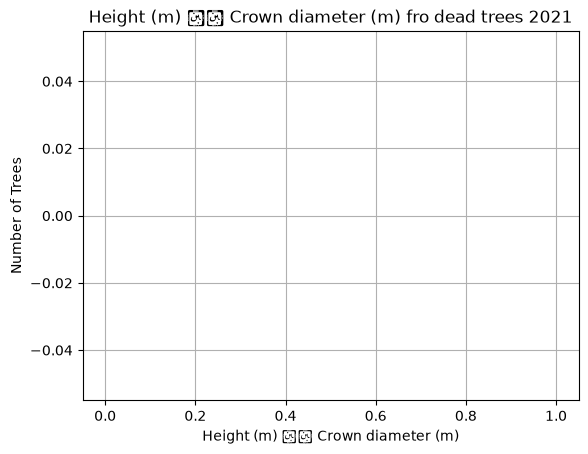

ValueError: Data cannot be log-scaled because all values are <= 0.

<Figure size 700x700 with 1 Axes>

In [14]:
biomass16["height x crown diameter"] = biomass16["diameter"] * biomass16["treeheight"]
biomass21["height x crown diameter"] = biomass21["diameter"] * biomass21["treeheight"]

biomass21["height x crown diameter"].hist(bins=50)
plt.title("Height (m) ﷿﷿ Crown diameter (m) fro dead trees 2021")
plt.xlabel("Height (m) ﷿﷿ Crown diameter (m)")
plt.ylabel("Number of Trees")
plt.show()

biomass16["height x crown diameter"] = biomass16["diameter"] * biomass16["treeheight"]
biomass21["height x crown diameter"] = biomass21["diameter"] * biomass21["treeheight"]

fig, ax = plt.subplots(figsize=(7, 7))

conifers = biomass21[biomass21["treetype"] == "coniferous"]
broadleaved = biomass21[biomass21["treetype"] == "broadleaved"]

ax.scatter(conifers["height x crown diameter"], conifers["AGB"], color="darkgreen", marker="o", label="Gymnosperms")
ax.scatter(broadleaved["height x crown diameter"], broadleaved["AGB"], color="lightgreen", edgecolors="grey", marker="o", label="Angiosperms")

ax.set_xscale("log")
ax.set_yscale("log")
x_ticks = [0.05, 0.5, 5, 50, 500, 5000]
x_labels = ["0.05", "0.5", "5", "50", "500", "5000"]
ax.set_xticks(x_ticks)
ax.set_xticklabels(x_labels)

y_ticks = [0.01, 0.1, 1, 10, 100, 1000, 10000, 100000]
y_labels = ["0.01", "0.1", "1", "10", "100", "1000", "10 000", "100 000"]
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)

ax.set_xlabel("Height (m) ﷿﷿ Crown diameter (m)", fontsize=12)
ax.set_ylabel("Aboveground biomass (kg)", fontsize=12)

ax.legend(loc="lower right", frameon=False, fontsize=11)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.show()

![plot from publication](plot_from_publication.png)